Sample langgraph example

In [1]:
#creating a programmin assistant, chaining workflows

In [1]:
import os
from dotenv import load_dotenv
import warnings
from typing import Literal, TypedDict
load_dotenv()
os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")
Weather_API_Key = os.getenv("WEATHER_API_KEY")


In [2]:
import requests
from dotenv import load_dotenv
from langchain.chat_models import init_chat_model
from langchain_community.tools import DuckDuckGoSearchRun
from langchain_community.document_loaders import ArxivLoader
from langchain_tavily import TavilySearch
from langchain.tools import tool
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import END, START, StateGraph

from pydantic import BaseModel, Field

from langchain.messages import HumanMessage, SystemMessage, AIMessage, ToolMessage

C:\Users\ramma\AppData\Local\Temp\ipykernel_17428\3036189316.py:4: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools import DuckDuckGoSearchRun


In [3]:
from langchain.chat_models import init_chat_model

llm_groq_1 = init_chat_model(
    model="openai/gpt-oss-120b", 
    model_provider="groq",
    metadata={
        "ls_provider": "groq", 
        "ls_model_name": "openai/gpt-oss-120b"
    }
)
llm_groq_2 = init_chat_model(
    model="qwen/qwen3.8-27b", 
    model_provider="groq",
    metadata={
        "ls_provider": "groq", 
        "ls_model_name": "qwen/qwen3.8-27b"
    }
)


# get rag documents

In [4]:
import requests
from langchain_core.documents import Document

from langchain_core.vectorstores import InMemoryVectorStore

from langchain_openai import OpenAIEmbeddings

from langchain_text_splitters import RecursiveCharacterTextSplitter

DOCS_BASE = "https://docs.langchain.com"

# Curated LangChain OSS pages for this tutorial. Expand this list or parse
# URLs from https://docs.langchain.com/llms.txt to index more of the site.
DOC_PATHS = [
    "oss/python/langchain/agents",
    "oss/python/deepagents/rag",
    "oss/python/langchain/tools",
    "oss/python/langchain/models",
    "oss/python/deepagents/retrieval",
    "oss/python/langchain/knowledge-base",
    "oss/python/langchain/middleware",
    "oss/python/deepagents/overview",
    "oss/python/deepagents/subagents",
    "oss/python/deepagents/streaming",
    "oss/python/deepagents/frontend/subagent-streaming",
    "oss/python/deepagents/backends",
    "oss/python/langgraph/overview",
    "oss/python/langgraph/quickstart",
]

In [19]:
from requests.exceptions import RequestException

def getDocument()->list[Document]:
    """Extract online document and return"""
    docs: list[Document] = []
    for path in DOC_PATHS:
        try:
            url = f"{DOCS_BASE}/{path}.md"
            response = requests.get(url, timeout=20)
        except RequestException as e:
            continue
        source = f"{DOCS_BASE}/{path}"
        docs.append(Document(page_content=response.text, metadata={"source":source}))

    return docs

In [20]:
getDocument()

[Document(metadata={'source': 'https://docs.langchain.com/oss/python/langchain/agents'}, page_content='> ## Documentation Index\n> Fetch the complete documentation index at: https://docs.langchain.com/llms.txt\n> Use this file to discover all available pages before exploring further.\n\n# Agents\n\n> Build a LangChain agent: a model calling tools in a loop until a task is complete, shaped by a harness of prompt, tools, and middleware.\n\nAn agent is a model calling tools in a loop until a given task is complete.\n\n![Core agent loop diagram](https://mintcdn.com/langchain-5e9cc07a/jtty0O--UJOKG0nK/oss/images/core_agent_loop.svg?fit=max\\&auto=format\\&n=jtty0O--UJOKG0nK\\&q=85\\&s=4b4cbb497b6273758a565de1bc90ece0)\n\nA harness is everything around that loop: the prompt, the tools, and any middleware that shapes the model\'s behavior.\n\n> [!NOTE]\n>\n> **Agent = Model + Harness**\n>\n> The job of a harness: get the model the right context at the right time for the given task.\n\n[`creat

In [21]:
print(getDocument()[0].page_content)

> ## Documentation Index
> Fetch the complete documentation index at: https://docs.langchain.com/llms.txt
> Use this file to discover all available pages before exploring further.

# Agents

> Build a LangChain agent: a model calling tools in a loop until a task is complete, shaped by a harness of prompt, tools, and middleware.

An agent is a model calling tools in a loop until a given task is complete.

![Core agent loop diagram](https://mintcdn.com/langchain-5e9cc07a/jtty0O--UJOKG0nK/oss/images/core_agent_loop.svg?fit=max\&auto=format\&n=jtty0O--UJOKG0nK\&q=85\&s=4b4cbb497b6273758a565de1bc90ece0)

A harness is everything around that loop: the prompt, the tools, and any middleware that shapes the model's behavior.

> [!NOTE]
>
> **Agent = Model + Harness**
>
> The job of a harness: get the model the right context at the right time for the given task.

[`create_agent`](https://reference.langchain.com/python/langchain/agents/factory/create_agent) is a highly configurable harness. At its

In [24]:
all_documents = getDocument()

In [26]:
#split the documents
text_splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=200)
all_splitted_documents = text_splitter.split_documents(all_documents)
print(f"No. of splits: {len(all_splitted_documents)}")

No. of splits: 805


## embedding

In [10]:
from langchain_huggingface import HuggingFaceEmbeddings

embeddings = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-mpnet-base-v2",
    encode_kwargs={"normalize_embeddings": True,
            'batch_size':32
                   },
    
)

c:\Users\ramma\Documents\YTLLMS\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\ramma\Documents\YTLLMS\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\ramma\.cache\huggingface\hub\models--sentence-transformers--all-mpnet-base-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In 

In [28]:
vector = embeddings.embed_documents("Hi")
print(len(vector[0]))
print(vector)

768
[[-0.022447852417826653, 0.0033181996550410986, 0.00305833388119936, -0.04091046750545502, -0.06324907392263412, 0.01245295163244009, -0.04883608594536781, 0.04409323260188103, 0.05960606783628464, 0.021306661888957024, 0.058976080268621445, -0.03063606657087803, -0.010807662270963192, -0.03278112784028053, -0.0006939569720998406, -0.061304908245801926, 0.030216388404369354, -0.006210124120116234, -0.08789143711328506, -0.045235101133584976, -0.02809966541826725, 0.002106448169797659, -0.011054001748561859, -0.025122934952378273, 0.03683074563741684, 0.024624640122056007, -0.0021649699192494154, 0.019194306805729866, -0.016108453273773193, -0.035833295434713364, 0.006631074007600546, 0.029264746233820915, 0.013039152137935162, 0.01209847629070282, 2.0016179860249395e-06, -0.02395768091082573, 0.007679809350520372, -0.047848720103502274, -0.04861022159457207, 0.013016249984502792, 0.0577659085392952, 0.01301886048167944, -0.030583545565605164, 0.01682998798787594, 0.0374009571969509

## vector store

In [29]:
from langchain_chroma import Chroma

vector_store = Chroma(
    collection_name="example_collection",
    embedding_function=embeddings,
    persist_directory="./chroma_langchain_db",  # Where to save data locally, remove if not necessary
)

In [31]:
vector_store.add_documents(documents=all_splitted_documents)

KeyboardInterrupt: 

In [ ]:
index_documents = vector_sotre.add(all_splitted_documents)

In [ ]:
vector_store.similarity_search_with_score(query="How to create a langchain agent?")

In [33]:
retriever = vector_store.as_retriever(search_kwargs={'k':1})
retriever.invoke(input="How to create langgraph agent?")

ImportError: cannot import name '_get_tracer_project' from 'langchain_core.tracers.context' (c:\Users\ramma\Documents\YTLLMS\.venv\Lib\site-packages\langchain_core\tracers\context.py)

In [ ]:
retriever.invoke(input="how to create a langgraph agent?")

In [ ]:
import json

def rag_retriever(query:str)->str:
    """RAG retriver tool to return context based on user query"""
    response = retriever.invoke(input = query)
    return json.dumps(response)

# create langchain agent and add rag_retriever as a tool. 

# last class stuff

In [39]:
#create the assistant
from typing_extensions import TypedDict
class ResearchAssistant(TypedDict):
    """"""
    user_query:str
    routes:list[str]
    web_info:str
    weather_info: str
    synthesizer:str

In [14]:
# create routing node
initial_state = {
    "user_query" : "What is the weather in Peoria? who is favored to win in the midterms in USA? what is NLPs?"
}

In [15]:
from pydantic import BaseModel, Field
from typing_extensions import Literal
class getRoute(BaseModel):
    routes: list[Literal["web", "weather"]] = Field(description="""return web route if user query is about news, current affairs, or internet search related, 
    return weather if user query is about weather of a city""")

In [16]:
model_routes = llm_groq_1.with_structured_output(getRoute)

In [18]:
#test the model
model_routes.invoke([
    SystemMessage(content="You are a helpful router."),
    HumanMessage(content=initial_state["user_query"])
])

getRoute(routes=['weather', 'web'])

In [45]:
# routing node definition
def routing(state:ResearchAssistant)->ResearchAssistant:
    """Generate routes based on the user query"""
    response = model_routes.invoke([
        SystemMessage(content="You are a helpful router."),
        HumanMessage(content=state["user_query"])
    ])
    return {"routes":response.routes}

In [20]:
routing(initial_state)

{'routing': ['weather', 'web']}

In [21]:
class getLocation(BaseModel):
    location:str=Field(description="Extract the location from the user query")

In [25]:
model_location = llm_groq_1.with_structured_output(getLocation)

In [26]:
model_location.invoke("Weather in Mexico city")

getLocation(location='Mexico City')

In [27]:
def weather_info(state:ResearchAssistant)->ResearchAssistant:
    """Return weather information based on a given location"""
    response = model_location.invoke(state["user_query"])
    weather = getweather.invoke(response.location)
    return {"weather_info":weather}

In [30]:
weather_info(initial_state)

{'weather_info': {'coord': {'lon': -89.7668, 'lat': 40.7667},
  'weather': [{'id': 800,
    'main': 'Clear',
    'description': 'clear sky',
    'icon': '01d'}],
  'base': 'stations',
  'main': {'temp': 77.2,
   'feels_like': 76.64,
   'temp_min': 76.1,
   'temp_max': 78.62,
   'pressure': 1020,
   'humidity': 43,
   'sea_level': 1020,
   'grnd_level': 994},
  'visibility': 10000,
  'wind': {'speed': 13.8, 'deg': 190, 'gust': 23.02},
  'clouds': {'all': 0},
  'dt': 1793222733,
  'sys': {'type': 1,
   'id': 5354,
   'country': 'US',
   'sunrise': 1793190283,
   'sunset': 1793228446},
  'timezone': -18000,
  'id': 4905697,
  'name': 'Peoria',
  'cod': 200}}

In [31]:
def web_info(state:ResearchAssistant)->ResearchAssistant:
    """Return web info based on user query"""
    response = web_search.invoke({"query":state["user_query"]})
    return {"web_info":response}


In [32]:
web_info(initial_state)

{'web_info': {'query': 'What is the weather in Peoria? who is favored to win in the midterms in USA? what is NLPs?',
  'follow_up_questions': None,
  'answer': None,
  'images': [],
  'results': [{'title': 'Weather in Peoria',
    'url': 'https://www.weatherapi.com/',
    'content': "{'error': {'code': 2007, 'message': 'API key has reached maximum calls per month allowed limit.'}}",
    'score': 0.8794778,
    'raw_content': None,
    'id': '70366c-00'},
   {'url': 'https://weatherspark.com/h/y/12709/2026/Historical-Weather-during-2026-in-Peoria-Illinois-United-States',
    'title': 'Peoria 2026 Past Weather (Illinois, United States)',
    'content': 'Today Yesterday Oct 2026    194019501960197019801990200020102020    2017201820192020202120222023202420252026    SpringSummerFallWinter JanFebMarAprMayJunJulAugSepOctNov Dec # 2026 Weather History in Peoria Illinois, United States The data for this report comes from the General Downing - Peoria International Airport. See all nearby weather

In [51]:
def select_specialist(state:ResearchAssistant)->list:
    """Based on user query return a list of destinations"""
    destinations=[]
    if 'web' in state['routes']:
        destinations.append("web_info")
    if 'weather' in state['routes']:
        destinations.append('weather_info')
    else:
        destinations.append('synthesizer')
    return destinations

In [52]:
#define synthesizer node
def synthesizer(state:ResearchAssistant)->ResearchAssistant:
    """Based on the evidence and user query return the final answer"""
    evidence = []
    if state["web_info"]:
        evidence.append(f"web info: \n\n {state['web_info']}")
    if state["weather_info"]:
        evidence.append(f"Weather info: \n\n {state['weather_info']}")
    response = llm_groq_1.invoke([
        SystemMessage(content=f"""You are a final synthesizer. Generate final answer based on user query {state['user_query']}
and evidence that you received from other nodes. Evidence: {evidence}. if there is no evidence answer on your own. """)
    ])
    return {"synthesizer":response}

In [53]:
from langgraph.graph import StateGraph, START, END

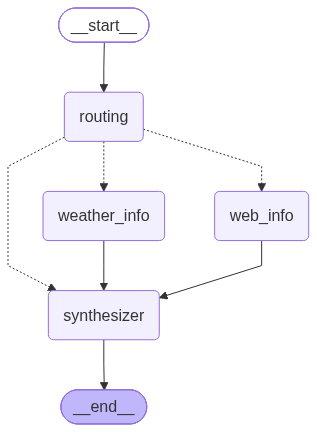

In [54]:
graph = StateGraph(ResearchAssistant)
graph.add_node(routing)
graph.add_node(web_info)
graph.add_node(synthesizer)
graph.add_node(weather_info)

graph.add_edge(START, "routing")
graph.add_conditional_edges("routing", select_specialist, ["web_info", "weather_info", "synthesizer"])
graph.add_edge("web_info", "synthesizer")
graph.add_edge("weather_info", "synthesizer")
graph.add_edge("synthesizer", END)

graph = graph.compile()
graph



In [55]:
try: 
    response = graph.invoke(initial_state)
    print(response["synthesizer"])
except Exception as e:
    print(f"error:{e}")

content="**1. Weather in Peoria (Illinois) –\u202fCurrent conditions (Oct\u202f28\u202f2026)**  \n\n| Element | Value |\n|---------|-------|\n| Temperature | **77\u202f°F** (≈\u202f25\u202f°C) |\n| Sky | **Clear** – no clouds reported |\n| Humidity | **43\u202f%** |\n| Wind | **13.8\u202fmph** from the south‑south‑west (190°) with gusts up to **23\u202fmph** |\n| Visibility | 10\u202fkm (clear) |\n| Pressure | 1019\u202fhPa |\n| Sunrise / Sunset (local) | 06:31\u202fam / 06:07\u202fpm (approx.) |\n\n*Evidence:* The live‑weather JSON returned for Peoria shows a temperature of 77.16\u202f°F, clear‑sky conditions, 43\u202f% humidity, and a 13.8\u202fmph wind from 190° with gusts of 23\u202fmph【'Weather info': {'main': {'temp': 77.16, 'humidity': 43}, 'weather': [{'main': 'Clear'}], 'wind': {'speed': 13.8, 'deg': 190, 'gust': 23.02}}】.  \n\n---\n\n**2. Who is favored to win the 2026 U.S. midterm elections?**  \n\n*No direct evidence was supplied for this question, so the answer is based on

# from last class

In [ ]:
#create code_generation state
def code_generation(state: ProgrammingState)->ProgrammingState:
    """Generate code based on user request"""

    prompt = f"""
    You are in expert in {state["programming_language"]}. 
    Generate the code based on the following requests: 
    {state["user_requests"]}

    Requirements: 
    - Generate just source code 
    """

    response = llm_groq_1.invoke(prompt)

    return {"code_generation": response.content}

In [ ]:
def code_explanation(state:ProgrammingState)->ProgrammingState:
    """Explain the generated code"""
    prompt = f"""
    You are an instructor of Computer Science courses. 
    Exaplain the following code {state["code_generation"]} based on the 
    {state["user_requests"]}

    Requirements: 
    - explain the code with a small example
    """
    response = llm_groq_1.invoke(prompt)
    return {"code_explanation":response.content}

In [ ]:
def complexity_analysis(state:ProgrammingState)->ProgrammingState:
    """Do the complexity analysis of generated code"""
    prompt = f"""
    You are an instructor of Computer Science courses. 
    Analyse the time and space complexity of code {state["code_generation"]} based on the 
    {state["user_requests"]}

    Requirements: 
    - Use the big-O complexity 
    - Find best-case, average-case and worst-case complexity analysis 
    """
    response = llm_groq_1.invoke(prompt)
    return {"complexity_analysis":response.content}

In [ ]:
def final_report(state: ProgrammingState)->ProgrammingState:
    """Generate final report"""
    final_report = f"""

    Programming Assistant Final Report
    ==================================
    
    {state["programming_language"]}

    User requests:
    ---------------

    {state["user_requests"]}

    Generated code: 
    ----------------
    
    {state["code_generation"]}

    Code Explanation:
    -------------------
    {state["code_explanation"]}

    Complexity Analysis: 
    -----------------------
    {state["complexity_analysis"]}

    """

    return {"final_report":final_report}

# tools & tool nodes

In [29]:
##create tools
import requests
from langchain.tools import tool
url = "https://api.openweathermap.org/data/2.5/weather?"

@tool
def getweather(location: str) -> str:
    """Take the location and return the current weather."""
    params = {
        "q": location, 
        "appid": Weather_API_Key, 
        "units": "imperial"
    }

    try: 
        response = requests.get(url, params=params, timeout=10)
        return response.json()
    except Exception:
        return "The requested weather information is unavailable."

from langchain_tavily import TavilySearch
from langchain_community.tools import DuckDuckGoSearchRun

web_search = TavilySearch(
    max_results=3, 
    topic="general", 
    search_depth="basic"
)
duck_search = DuckDuckGoSearchRun()

tools = [getweather, web_search, duck_search]

In [ ]:
tool_names = {tool.name: tool for tool in tools}
tool_names

{'getweather': StructuredTool(name='getweather', description='Take the location and return the current weather.', args_schema=<class 'langchain_core.utils.pydantic.getweather'>, func=<function getweather at 0x00000201B340EF20>),
 'tavily_search': TavilySearch(search_depth='basic', max_results=3, topic='general', api_wrapper=TavilySearchAPIWrapper(tavily_api_key=SecretStr('**********'), api_base_url=None)),
 'duckduckgo_search': DuckDuckGoSearchRun(api_wrapper=DuckDuckGoSearchAPIWrapper(region='wt-wt', safesearch='moderate', time='y', max_results=5, backend='auto', source='text'))}

In [ ]:
# create and compile the graph

from langgraph.graph import StateGraph, MessagesState, START, END
from langchain.messages import SystemMessage, HumanMessage, AIMessage


In [ ]:
llm_with_tools = llm_groq_1.bind_tools(tools)
def llm_node(state:MessagesState)->MessagesState:
    """response - take current state and return the next state. """
    response = llm_with_tools.invoke([
        SystemMessage(content="You are a helpful chatbot assistant. Use getweather tool for answering weather related queries. Use web_search tool for recent events, finance, news, pop culture and internet search. Use web_search for any queries involving today or the current year (2026). Use duck_search when web_search is not available or returns no results. For normal chat conversation, don't use a tool, just answer on your own.")
    ] + state["messages"]
    )
    return {"messages": [response]}

In [ ]:
# create the tool node
def tool_node(state:MessagesState)->str:
    """node for tools"""
    last_message = state["messages"][-1]
    tool_messages = []
    for tool_call in last_message.tool_calls:
        tool_name = tool_call["name"]
        selected_tool = tool_names[tool_name]
        tool_message = selected_tool.invoke(tool_call)
        tool_messages.append(tool_message)

    return {"messages":tool_message}



In [ ]:
def should_continue(state:MessagesState)->str:
    """return should go next"""
    last_message = state["messages"][-1]
    if last_message.tool_calls:
        return "tool_node"
    return END

In [ ]:
# add end condition
def tool_condition(state:MessagesState)->str:
    last_message = state["messages"][-1]
    if(last_message.tool_calls):
        return "tool_node"

    return END

# graph

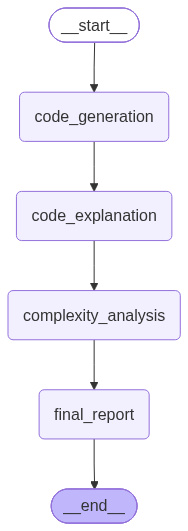

In [ ]:
graph = StateGraph(ProgrammingState)

graph.add_node(code_generation)
graph.add_node(code_explanation)
graph.add_node(complexity_analysis)
graph.add_node(final_report)

#edges 

graph.add_edge(START,"code_generation")
graph.add_edge("code_generation","code_explanation")
graph.add_edge("code_explanation","complexity_analysis")
graph.add_edge("complexity_analysis","final_report")
graph.add_edge("final_report",END)


graph = graph.compile()
graph

In [ ]:
initial_state = {
    "user_requests":"""Write binary search code. Assume you have a sorted data set and a target
    element. Return found index for the successful search, otherwise return -1""",
    "programming_language":"java"
}

In [ ]:
result = graph.invoke(initial_state)
#print(result)
print(result["code_generation"])
print("\n\n")
print(result["code_explanation"])

# %%
print(result["final_report"])

```java
public class BinarySearch {

    /**
     * Performs binary search on a sorted array.
     *
     * @param sortedArray the array must be sorted in ascending order
     * @param target      the element to search for
     * @return the index of the target if found; otherwise -1
     */
    public static int binarySearch(int[] sortedArray, int target) {
        int left = 0;
        int right = sortedArray.length - 1;

        while (left <= right) {
            int mid = left + (right - left) / 2; // avoid overflow

            if (sortedArray[mid] == target) {
                return mid;
            } else if (sortedArray[mid] < target) {
                left = mid + 1;
            } else {
                right = mid - 1;
            }
        }

        return -1; // not found
    }

    // Example usage (optional)
    public static void main(String[] args) {
        int[] data = {1, 3, 5, 7, 9, 11, 13, 15};
        int target = 7;
        int index = binarySearch(data, target

# archive

In [ ]:
## invoke the graph
user_query = {
    "messages":[
        HumanMessage(content="What is AI? Please answer in bullet form.")
    ]
}

response = graph.invoke(user_query)

# print(response["messages"][-1].content)
for m in response["messages"]:
     m.pretty_print()

================================ Human Message =================================

What is AI? Please answer in bullet form.
================================== Ai Message ==================================

- **Artificial Intelligence (AI)** is the field of computer science focused on creating systems that can perform tasks that normally require human intelligence.  
- **Core capabilities** include learning, reasoning, problem‑solving, perception, language understanding, and decision‑making.  
- **Types of AI**  
  - *Narrow (or weak) AI*: Designed for a specific task (e.g., image recognition, chatbots).  
  - *General (or strong) AI*: Hypothetical systems that can understand, learn, and apply knowledge across any domain like a human.  
- **Key techniques**  
  - *Machine Learning*: Algorithms that improve performance from data (e.g., supervised, unsupervised, reinforcement learning).  
  - *Deep Learning*: Neural networks with many layers that excel at complex pattern recognition (e.g.

In [ ]:
llm_node(user_query)

{'messages': [AIMessage(content='- **Artificial Intelligence (AI)**: The field of computer science focused on creating systems that can perform tasks that normally require human intelligence.  \n- **Core capabilities**:  \n  - Learning from data (machine learning)  \n  - Reasoning and problem‑solving  \n  - Perceiving the world (computer vision, speech/audio processing)  \n  - Understanding and generating natural language (NLP)  \n  - Planning and decision‑making under uncertainty  \n- **Main approaches**:  \n  - **Rule‑based systems** – explicit logical rules programmed by humans  \n  - **Machine learning** – algorithms that improve performance from experience, especially deep learning with neural networks  \n  - **Hybrid systems** – combine rules, learning, and statistical methods  \n- **Common categories**:  \n  - **Narrow (or weak) AI** – specialized for a single task (e.g., image classification, recommendation engines)  \n  - **General (or strong) AI** – hypothetical systems with 

In [ ]:
user_query = {
    "messages":[
        HumanMessage(content="give a dad joke/pun in malay")
    ]
}

In [ ]:

#call the graph
try:
    response = graph.invoke(user_query)
except Exception as e:
    print(f"Error.{e}")
    
print(response)

{'messages': [HumanMessage(content='give a dad joke/pun in malay', additional_kwargs={}, response_metadata={}, id='5772747a-ba80-41c3-96bb-922d63b17643'), AIMessage(content='**Joke:**  \nKenapa durian tak pernah dapat kerja?  \n\nKerana dia selalu “bonggol” bila temuduga!  \n\n*(Bonggol = “bongkar”/“bongkar” dalam konteks kerja, tapi juga maksudnya durian yang berbonggol‑bonggol.)*  ', additional_kwargs={'reasoning_content': 'We need to respond with a dad joke/pun in Malay. Should be appropriate, friendly. Provide a joke. Probably include translation? Not required but could be helpful. Ensure it\'s a dad joke style: punny, maybe about "kucing" or "pisang". Let\'s produce one.'}, response_metadata={'token_usage': {'completion_tokens': 138, 'prompt_tokens': 90, 'total_tokens': 228, 'completion_time': 0.289634265, 'completion_tokens_details': {'reasoning_tokens': 60}, 'prompt_time': 0.004000102, 'prompt_tokens_details': None, 'queue_time': 0.168262951, 'total_time': 0.293634367}, 'model_n

In [ ]:
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

give a dad joke/pun in malay
================================== Ai Message ==================================

**Joke:**  
Kenapa durian tak pernah dapat kerja?  

Kerana dia selalu “bonggol” bila temuduga!  

*(Bonggol = “bongkar”/“bongkar” dalam konteks kerja, tapi juga maksudnya durian yang berbonggol‑bonggol.)*
